# PsyDefDetect — EDA & Baseline
**Notebook:** `01_eda_baseline.ipynb`  
**Pipeline Stage:** Module 0 (Config) + Module 1 (EDA + Sanity Baseline)  
**Dataset:** 9-class DMRS (1864 train / 472 test)

---
## Module 0 — Config & Reproducibility

In [1]:
import os
def _detect_project_root() -> Path:
    # 1. Environment variable override
    env_data = os.environ.get("DATA_DIR")
    if env_data and Path(env_data).exists():
        return Path(env_data).resolve()
    
    # 2. Check current working directory
    cwd = Path.cwd().resolve()
    if (cwd / "train.json").exists():
        return cwd
    
    # 3. Check parents (if running from a subfolder)
    for p in list(cwd.parents):
        if (p / "train.json").exists():
            return p
            
    # 4. Check subdirectories of cwd (e.g. if Jupyter was launched in /workspace or /root and repo is inside)
    try:
        for p in cwd.glob("**/train.json"):
            if ".ipynb_checkpoints" not in str(p):
                return p.parent.resolve()
    except Exception:
        pass

    # 5. Check common cloud GPU locations (/workspace, /root)
    for base in ["/workspace", "/root", str(Path.home())]:
        try:
            base_path = Path(base)
            if base_path.exists():
                for p in base_path.glob("**/train.json"):
                    if ".ipynb_checkpoints" not in str(p):
                        return p.parent.resolve()
        except Exception:
            pass

    # 6. Fallback
    if os.name != "nt":
        return cwd
    return Path(r"c:\Users\Public\Documents\TA\Dataset")

_PROJECT_ROOT = _detect_project_root()

from dataclasses import dataclass, field
from pathlib import Path
from typing import List
import random, os

import numpy as np

@dataclass
class CFG:
    SEEDS: List[int]        = field(default_factory=lambda: [42, 2026, 777])
    MODEL_NAME_SMALL: str   = "Qwen/Qwen3-4B"
    MODEL_NAME_MAIN: str    = "Qwen/Qwen3-8B"
    DATA_DIR: str           = r"c:\Users\Public\Documents\TA\Dataset"
    ARTIFACT_DIR: str       = r"c:\Users\Public\Documents\TA\Dataset\artifacts"
    N_FOLDS: int            = 5
    MAX_HISTORY_TURNS: int  = 30
    MAX_LENGTH: int         = 1536

cfg = CFG()

# ── Create artifact subdirectories ──────────────────────────────────────────
for sub in [
    "splits",
    "stage1_qwen3_8b/seed_42",
    "stage2_sequential",
    "results",
]:
    Path(cfg.ARTIFACT_DIR, sub).mkdir(parents=True, exist_ok=True)
    print(f"  [mkdir] {Path(cfg.ARTIFACT_DIR, sub)}")

# ── Set random seeds ─────────────────────────────────────────────────────────
def set_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print(f"  [seed] torch seeded with {seed}")
    except ImportError:
        print("  [seed] torch not available — skipped")

set_seeds(cfg.SEEDS[0])
print("\nConfig ready:", cfg)


  [mkdir] c:\Users\Public\Documents\TA\Dataset\artifacts\splits
  [mkdir] c:\Users\Public\Documents\TA\Dataset\artifacts\stage1_qwen3_8b\seed_42
  [mkdir] c:\Users\Public\Documents\TA\Dataset\artifacts\stage2_sequential
  [mkdir] c:\Users\Public\Documents\TA\Dataset\artifacts\results


  [seed] torch seeded with 42

Config ready: CFG(SEEDS=[42, 2026, 777], MODEL_NAME_SMALL='Qwen/Qwen3-4B', MODEL_NAME_MAIN='Qwen/Qwen3-8B', DATA_DIR='c:\\Users\\Public\\Documents\\TA\\Dataset', ARTIFACT_DIR='c:\\Users\\Public\\Documents\\TA\\Dataset\\artifacts', N_FOLDS=5, MAX_HISTORY_TURNS=30, MAX_LENGTH=1536)


---
## Module 1 — EDA

### 1-0  Imports

In [2]:
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams.update({"figure.dpi": 150})
sns.set_theme(style="whitegrid", palette="muted")

DATA_DIR     = Path(cfg.DATA_DIR)
ARTIFACT_DIR = Path(cfg.ARTIFACT_DIR)
RESULTS_DIR  = ARTIFACT_DIR / "results"
SPLITS_DIR   = ARTIFACT_DIR / "splits"

LABEL_NAMES = [
    "No Defense",           # 0
    "Action",               # 1
    "Major Image-Distorting",# 2
    "Disavowal",            # 3
    "Minor Image-Distorting",# 4
    "Neurotic",             # 5
    "Obsessional",          # 6
    "High-Adaptive",        # 7
    "Needs More Info",      # 8
]

print("Imports OK")

Imports OK


### 1-1  Data Loading + Schema Validation

In [3]:
def load_dataset(path: Path) -> list:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

train_raw = load_dataset(DATA_DIR / "train.json")
test_raw  = load_dataset(DATA_DIR / "test.json")

print(f"Train samples : {len(train_raw):,}")
print(f"Test  samples : {len(test_raw):,}")

# ── Schema validation ────────────────────────────────────────────────────────
def validate_schema(samples: list, split_name: str) -> int:
    violations = []
    for i, s in enumerate(samples):
        last = s["dialogue"][-1]
        if last["speaker"] != "seeker":
            violations.append((i, s.get("id"), "last_speaker_not_seeker", last["speaker"]))
        if last["text"].strip() != s["current_text"].strip():
            violations.append((i, s.get("id"), "current_text_mismatch",
                               f"'{last['text'][:40]}' vs '{s['current_text'][:40]}'"))
    if violations:
        print(f"\n[{split_name}] ⚠ {len(violations)} violation(s):")
        for v in violations[:10]:
            print(" ", v)
    else:
        print(f"[{split_name}] ✓ All {len(samples):,} schema assertions passed")
    return len(violations)

train_violations = validate_schema(train_raw, "train")
test_violations  = validate_schema(test_raw,  "test")

Train samples : 1,864
Test  samples : 472
[train] ✓ All 1,864 schema assertions passed
[test] ✓ All 472 schema assertions passed


In [4]:
# ── Build DataFrames ─────────────────────────────────────────────────────────
def build_df(samples: list) -> pd.DataFrame:
    rows = []
    for s in samples:
        rows.append({
            "id"           : s["id"],
            "dialogue_id"  : s["dialogue_id"],
            "current_text" : s["current_text"],
            "label"        : s["label"],
            "n_turns"      : len(s["dialogue"]),
            "dialogue"     : s["dialogue"],
        })
    return pd.DataFrame(rows)

train_df = build_df(train_raw)
test_df  = build_df(test_raw)

print("train_df shape:", train_df.shape)
train_df.head(3)

train_df shape: (1864, 6)


,id,dialogue_id,current_text,label,n_turns,dialogue
0,train_00001,ESConv_001,hi,0,1,"[{'text': 'hi', 'speaker': 'seeker'}]"
1,train_00002,ESConv_001,"going smooth, i need to get a nice and a surpr...",2,3,"[{'text': 'hi', 'speaker': 'seeker'}, {'text':..."
2,train_00003,ESConv_001,"that is the major concern, the gift is once in...",7,7,"[{'text': 'hi', 'speaker': 'seeker'}, {'text':..."


### 1-2  Class Distribution

In [5]:
def class_dist_table(df: pd.DataFrame, split: str) -> pd.DataFrame:
    counts = df["label"].value_counts().sort_index()
    total  = len(df)
    tbl = pd.DataFrame({
        "label_id"  : counts.index,
        "label_name": [LABEL_NAMES[i] for i in counts.index],
        "count"     : counts.values,
        "proportion": (counts.values / total * 100).round(2),
    })
    print(f"\n── {split} class distribution ──")
    print(tbl.to_string(index=False))
    return tbl

train_dist = class_dist_table(train_df, "TRAIN")
test_dist  = class_dist_table(test_df,  "TEST")


── TRAIN class distribution ──
 label_id             label_name  count  proportion
        0             No Defense    296       15.88
        1                 Action    108        5.79
        2 Major Image-Distorting     61        3.27
        3              Disavowal     99        5.31
        4 Minor Image-Distorting     84        4.51
        5               Neurotic     48        2.58
        6            Obsessional    172        9.23
        7          High-Adaptive    968       51.93
        8        Needs More Info     28        1.50

── TEST class distribution ──
 label_id             label_name  count  proportion
        0             No Defense     75       15.89
        1                 Action     28        5.93
        2 Major Image-Distorting     16        3.39
        3              Disavowal     25        5.30
        4 Minor Image-Distorting     21        4.45
        5               Neurotic     13        2.75
        6            Obsessional     44        9.32
 

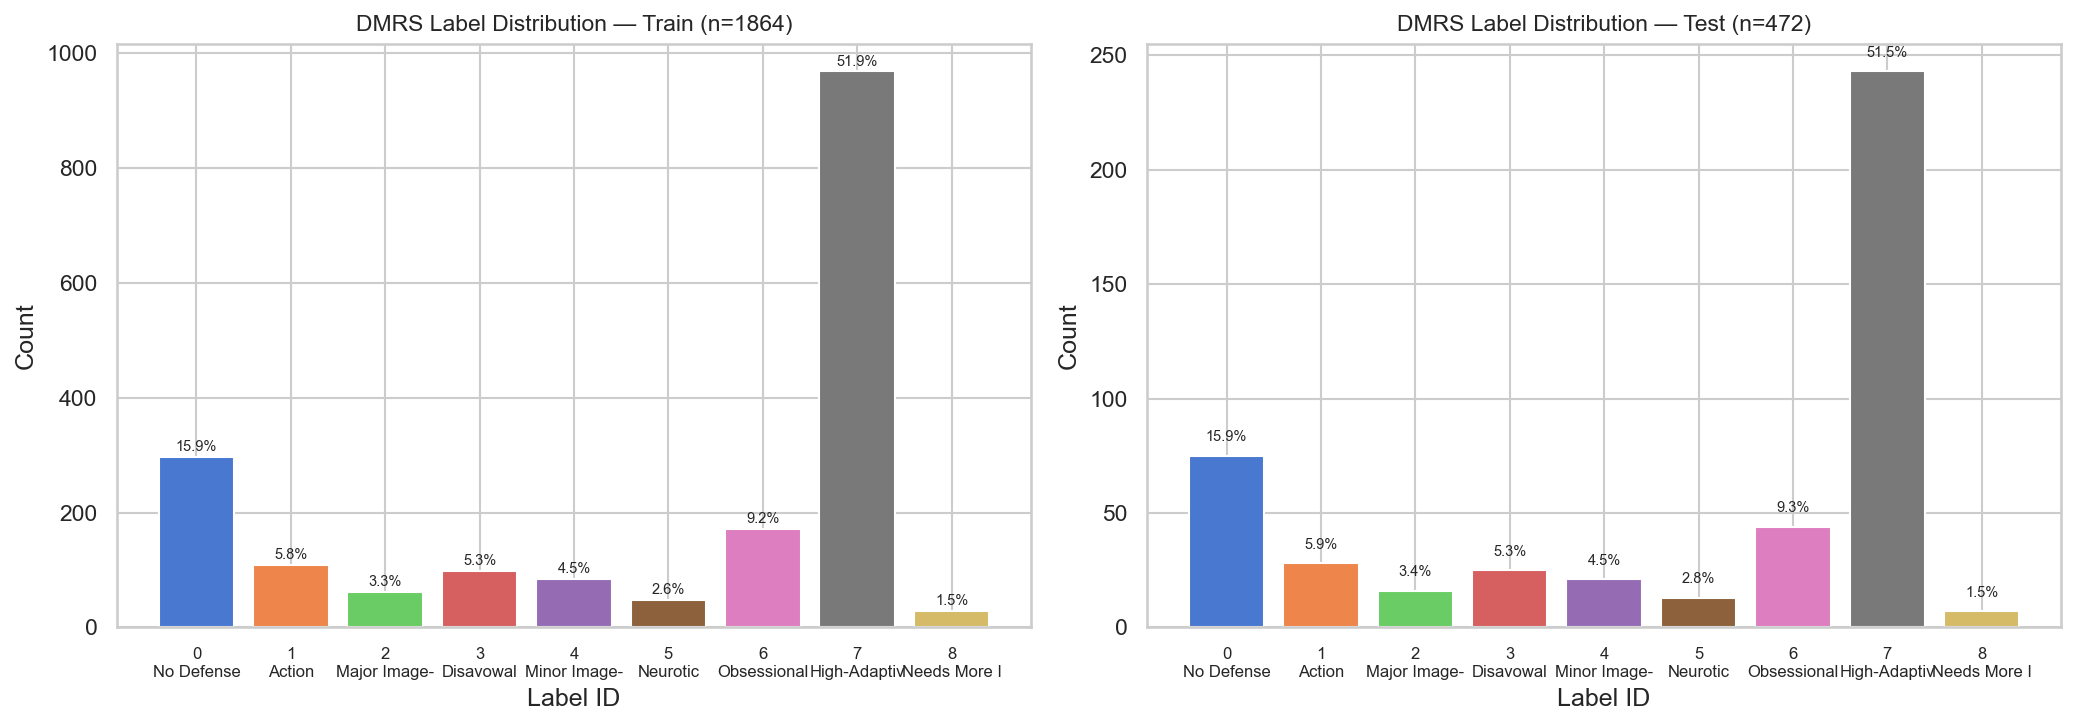

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\results\label_distribution.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, dist, title in zip(axes,
                            [train_dist, test_dist],
                            ["Train (n=1864)", "Test (n=472)"]):
    bars = ax.bar(dist["label_id"], dist["count"],
                  color=sns.color_palette("muted", 9))
    ax.set_xticks(dist["label_id"])
    ax.set_xticklabels(
        [f"{i}\n{LABEL_NAMES[i][:12]}" for i in dist["label_id"]],
        fontsize=8, rotation=0)
    ax.set_title(f"DMRS Label Distribution — {title}", fontsize=11)
    ax.set_xlabel("Label ID")
    ax.set_ylabel("Count")
    for bar, pct in zip(bars, dist["proportion"]):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 5,
                f"{pct:.1f}%", ha="center", va="bottom", fontsize=7)

plt.tight_layout()
out = RESULTS_DIR / "label_distribution.png"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved → {out}")

### 1-3  Dialogue Overlap Audit

In [7]:
train_dlg = set(train_df["dialogue_id"].unique())
test_dlg  = set(test_df["dialogue_id"].unique())
shared    = train_dlg & test_dlg

print(f"Unique dialogue_ids  — train : {len(train_dlg):,}")
print(f"Unique dialogue_ids  — test  : {len(test_dlg):,}")
print(f"Shared dialogue_ids          : {len(shared):,}  (expected ≈ 189)")
assert 180 <= len(shared) <= 200, f"Unexpected shared count: {len(shared)}"

# Per-dialogue sample counts for shared dialogues
shared_summary = pd.merge(
    train_df.groupby("dialogue_id").size().rename("train_samples").reset_index(),
    test_df.groupby("dialogue_id").size().rename("test_samples").reset_index(),
    on="dialogue_id", how="inner"
)
print(f"\nPer-dialogue sample counts for shared dialogues (first 10):")
print(shared_summary.head(10).to_string(index=False))
print(f"\nTotal shared dialogues in table: {len(shared_summary)}")
print(f"Total train utterances from shared dialogues: {shared_summary['train_samples'].sum()}")
print(f"Total test  utterances from shared dialogues: {shared_summary['test_samples'].sum()}")

Unique dialogue_ids  — train : 200
Unique dialogue_ids  — test  : 189
Shared dialogue_ids          : 189  (expected ≈ 189)

Per-dialogue sample counts for shared dialogues (first 10):
dialogue_id  train_samples  test_samples
 ESConv_001              5             1
 ESConv_002              9             1
 ESConv_003             16             6
 ESConv_004             11             4
 ESConv_005              8             2
 ESConv_006              8             1
 ESConv_007              9             1
 ESConv_008              8             2
 ESConv_010              7             2
 ESConv_011              5             4

Total shared dialogues in table: 189
Total train utterances from shared dialogues: 1761
Total test  utterances from shared dialogues: 472


### 1-4  Empirical Trajectory Analysis (Transition Matrix)

In [8]:
# Sort by (dialogue_id, n_turns) to get temporal order
sorted_df = train_df.sort_values(["dialogue_id", "n_turns"]).copy()

# Build transition matrix: for each dialogue, consecutive (y_{t-1} -> y_t) pairs
trans_counts = np.zeros((9, 9), dtype=int)

for dlg_id, grp in sorted_df.groupby("dialogue_id", sort=False):
    labels = grp["label"].tolist()
    for prev, curr in zip(labels[:-1], labels[1:]):
        trans_counts[prev, curr] += 1

# Row-normalise to get transition probabilities
row_sums = trans_counts.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1  # avoid div-by-zero
trans_prob = trans_counts / row_sums

trans_df = pd.DataFrame(
    trans_prob,
    index=[f"{i}:{LABEL_NAMES[i][:14]}" for i in range(9)],
    columns=[f"{i}:{LABEL_NAMES[i][:14]}" for i in range(9)]
)

print("Transition count matrix (raw):")
print(pd.DataFrame(trans_counts,
                   index=[f"L{i}" for i in range(9)],
                   columns=[f"L{i}" for i in range(9)]))
print(f"\nTotal transitions: {trans_counts.sum():,}")

Transition count matrix (raw):
     L0  L1  L2  L3  L4  L5  L6   L7  L8
L0   58   7   7   4   9   9  19   96   2
L1    9  26   5   8   5   1   9   39   1
L2    5   6   8   5   5   1   6   22   1
L3   16  10   4   9   7   3  13   31   0
L4    8   6   2   8   8   3   9   33   1
L5    3   6   2   4   0   3   4   17   3
L6   11   9   5  17  12   4  25   78   6
L7  102  34  25  43  34  19  81  533  14
L8    2   3   1   0   1   0   1   18   0

Total transitions: 1,664


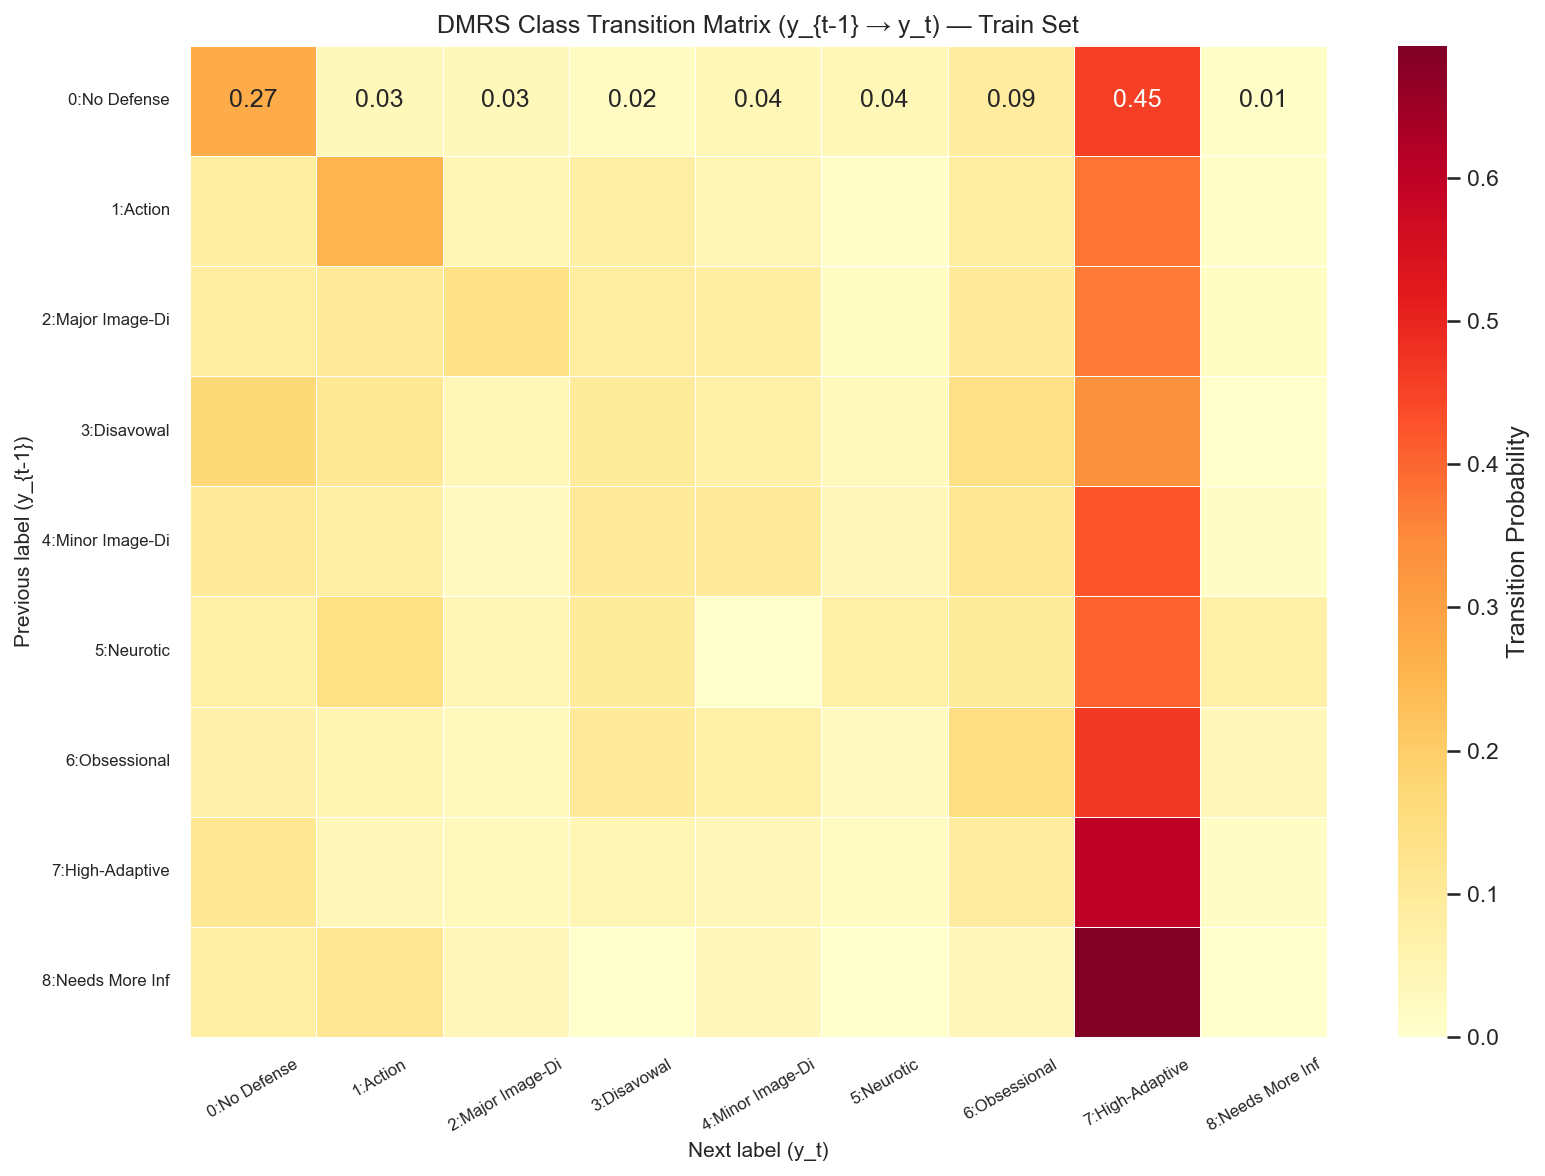

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\results\transition_matrix.png


In [9]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    trans_df, annot=True, fmt=".2f",
    cmap="YlOrRd", linewidths=0.4,
    ax=ax, cbar_kws={"label": "Transition Probability"}
)
ax.set_title("DMRS Class Transition Matrix (y_{t-1} → y_t) — Train Set", fontsize=12)
ax.set_xlabel("Next label (y_t)", fontsize=10)
ax.set_ylabel("Previous label (y_{t-1})", fontsize=10)
ax.tick_params(axis="x", rotation=30, labelsize=8)
ax.tick_params(axis="y", rotation=0,  labelsize=8)
plt.tight_layout()
out = RESULTS_DIR / "transition_matrix.png"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved → {out}")

### 1-5  Turn Length Distribution per Label

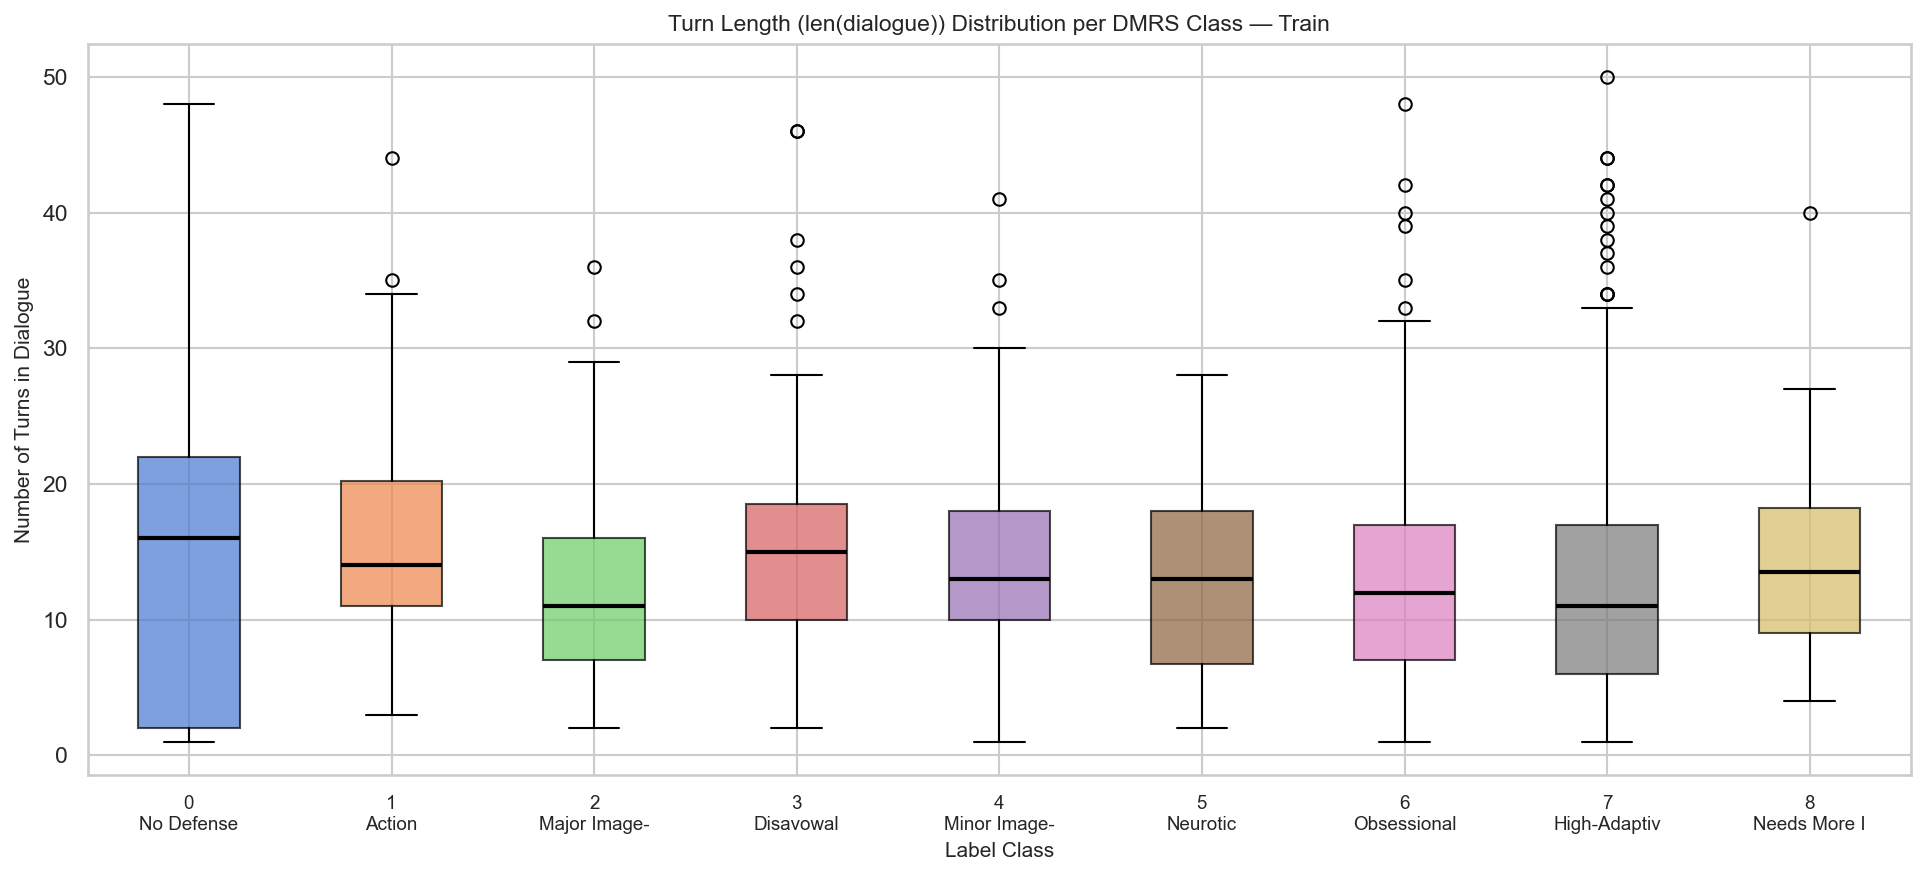

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\results\turn_length_per_class.png


In [10]:
fig, ax = plt.subplots(figsize=(13, 6))

data_by_label = [
    train_df.loc[train_df["label"] == i, "n_turns"].values
    for i in range(9)
]

bp = ax.boxplot(
    data_by_label,
    patch_artist=True,
    medianprops={"color": "black", "linewidth": 2},
)

palette = sns.color_palette("muted", 9)
for patch, color in zip(bp["boxes"], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_xticks(range(1, 10))
ax.set_xticklabels(
    [f"{i}\n{LABEL_NAMES[i][:12]}" for i in range(9)],
    fontsize=9
)
ax.set_title("Turn Length (len(dialogue)) Distribution per DMRS Class — Train", fontsize=11)
ax.set_xlabel("Label Class", fontsize=10)
ax.set_ylabel("Number of Turns in Dialogue", fontsize=10)
plt.tight_layout()
out = RESULTS_DIR / "turn_length_per_class.png"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved → {out}")

### 1-6  Token Length Audit

In [11]:
SYSTEM_PROMPT = """You are an expert psychotherapist and clinical psychologist specializing in defense mechanism analysis.
Your task is to classify the primary defense mechanism used by the SEEKER in their most recent utterance.

The 9 DMRS defense mechanism classes are:
  0 - No Defense: No discernible defense mechanism present.
  1 - Action: Acting out, impulsive behavior used to avoid affect.
  2 - Major Image-Distorting: Splitting, projective identification, autistic fantasy.
  3 - Disavowal: Denial, projection, rationalization.
  4 - Minor Image-Distorting: Omnipotence, idealization, devaluation.
  5 - Neurotic: Repression, reaction formation, displacement, undoing.
  6 - Obsessional: Isolation of affect, intellectualization.
  7 - High-Adaptive: Affiliation, altruism, anticipation, humor, self-assertion.
  8 - Needs More Info: Insufficient context to classify.

Analyze the dialogue and classify the SEEKER's last utterance. Output only the integer class label (0-8)."""

def build_prompt(sample: dict, max_history_turns: int = 30) -> str:
    """Construct the full prompt for a single sample."""
    # Part 1 — system / role instructions
    part1 = SYSTEM_PROMPT

    # Part 2 — dialogue history (all turns except the last one)
    history = sample["dialogue"][:-1]
    history = history[-max_history_turns:]  # keep last N turns
    if history:
        lines = []
        for turn in history:
            role = "SEEKER" if turn["speaker"] == "seeker" else "SUPPORTER"
            lines.append(f"{role}: {turn['text']}")
        part2 = "\n".join(lines)
    else:
        part2 = "[Start of conversation]"

    # Part 3 — current seeker utterance
    n_turns = len(sample["dialogue"])
    part3 = f"(Turn {n_turns})\nSEEKER: {sample['current_text']}"

    return f"{part1}\n\n{part2}\n\n{part3}"

# ── Load tokenizer ───────────────────────────────────────────────────────────
tokenizer = None
try:
    from transformers import AutoTokenizer
    print(f"Loading tokenizer: {cfg.MODEL_NAME_SMALL} …")
    tokenizer = AutoTokenizer.from_pretrained(
        cfg.MODEL_NAME_SMALL, trust_remote_code=True
    )
    print("Tokenizer loaded ✓")
except ImportError:
    print("⚠ WARNING: `transformers` is not installed — token length audit skipped.")
except Exception as e:
    print(f"⚠ WARNING: Could not load tokenizer ({e}) — token length audit skipped.")

C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading tokenizer: Qwen/Qwen3-4B …


C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Rian Chairul Ichsan\.cache\huggingface\hub\models--Qwen--Qwen3-4B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tokenizer loaded ✓


Tokenizing all train samples (this may take a minute) …



Token Length Statistics (train, n=1,864):
  Min    : 245
  Max    : 1,382
  Mean   : 560.5
  Median : 536.0
  P95    : 964.8
  P99    : 1160.2

  % within max_length=1024 : 96.83%
  % within max_length=1536 : 100.00%


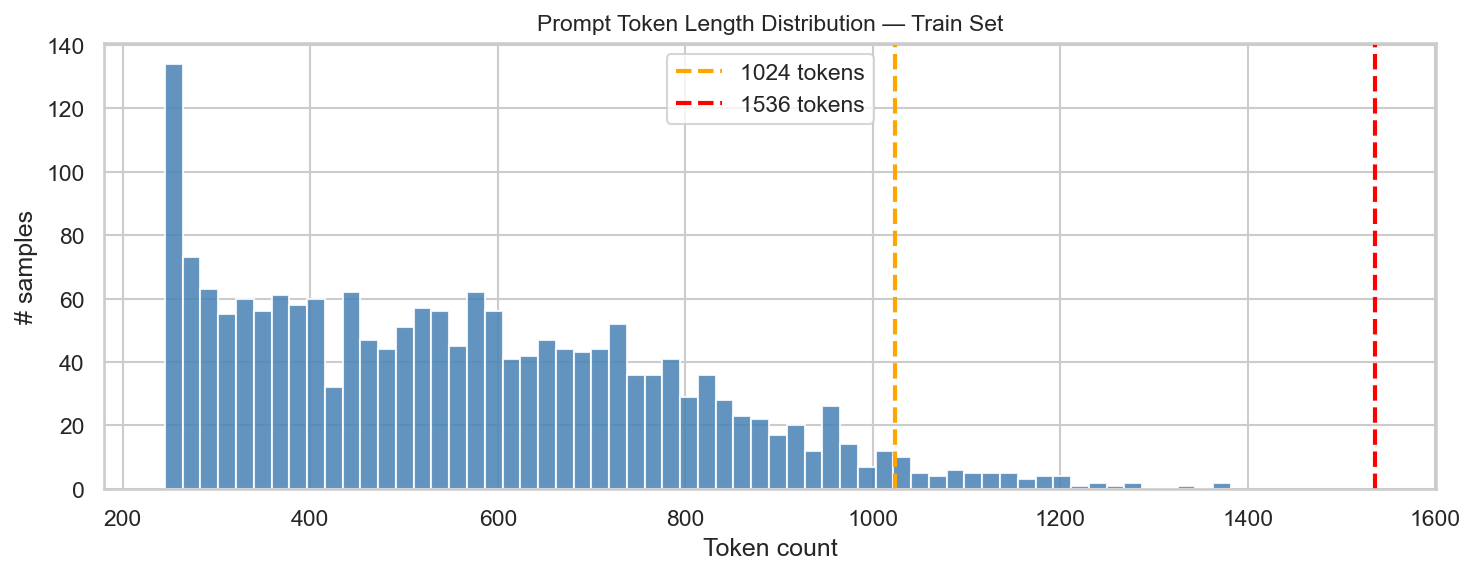

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\results\token_length_distribution.png


In [12]:
if tokenizer is not None:
    print("Tokenizing all train samples (this may take a minute) …")
    token_lengths = []
    for s in train_raw:
        prompt = build_prompt(s, cfg.MAX_HISTORY_TURNS)
        ids = tokenizer.encode(prompt, add_special_tokens=True)
        token_lengths.append(len(ids))

    token_lengths = np.array(token_lengths)
    n = len(token_lengths)

    pct_1024 = (token_lengths <= 1024).sum() / n * 100
    pct_1536 = (token_lengths <= 1536).sum() / n * 100

    print(f"\nToken Length Statistics (train, n={n:,}):")
    print(f"  Min    : {token_lengths.min():,}")
    print(f"  Max    : {token_lengths.max():,}")
    print(f"  Mean   : {token_lengths.mean():.1f}")
    print(f"  Median : {np.median(token_lengths):.1f}")
    print(f"  P95    : {np.percentile(token_lengths, 95):.1f}")
    print(f"  P99    : {np.percentile(token_lengths, 99):.1f}")
    print(f"\n  % within max_length=1024 : {pct_1024:.2f}%")
    print(f"  % within max_length=1536 : {pct_1536:.2f}%")

    # Histogram
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(token_lengths, bins=60, color="steelblue", edgecolor="white", alpha=0.85)
    ax.axvline(1024, color="orange", linewidth=2, linestyle="--", label="1024 tokens")
    ax.axvline(1536, color="red",    linewidth=2, linestyle="--", label="1536 tokens")
    ax.set_title("Prompt Token Length Distribution — Train Set", fontsize=11)
    ax.set_xlabel("Token count")
    ax.set_ylabel("# samples")
    ax.legend()
    plt.tight_layout()
    out = RESULTS_DIR / "token_length_distribution.png"
    plt.savefig(out, bbox_inches="tight")
    plt.show()
    print(f"Saved → {out}")
else:
    print("Skipping token length audit (tokenizer unavailable).")

### 1-7  Fold Assignment (StratifiedGroupKFold)

In [13]:
from sklearn.model_selection import StratifiedGroupKFold

# ── Compute seeker_turn_idx: 0-indexed rank of this utterance among
#    seeker utterances in its dialogue (sorted by n_turns / abs_turn_idx).
train_df = train_df.sort_values(["dialogue_id", "n_turns"]).copy()
train_df["seeker_turn_idx"] = (
    train_df.groupby("dialogue_id").cumcount()
)
train_df["abs_turn_idx"] = train_df["n_turns"]   # len(dialogue)

# ── StratifiedGroupKFold ─────────────────────────────────────────────────────
sgkf = StratifiedGroupKFold(n_splits=cfg.N_FOLDS, shuffle=True, random_state=42)

X      = train_df.index.values        # dummy X
y      = train_df["label"].values
groups = train_df["dialogue_id"].values

train_df["fold_id"] = -1
for fold, (tr_idx, val_idx) in enumerate(sgkf.split(X, y, groups)):
    train_df.iloc[val_idx, train_df.columns.get_loc("fold_id")] = fold

print("Fold distribution:")
print(train_df.groupby("fold_id")["label"].value_counts().unstack(fill_value=0))
print("\nSamples per fold:")
print(train_df["fold_id"].value_counts().sort_index())

Fold distribution:
label     0   1   2   3   4   5   6    7  8
fold_id                                    
0        68  21  13  17  16  11  33  180  5
1        55  26  14  14  15  11  35  189  6
2        49  21  11  34  23   8  46  197  3
3        77  23  14  17  15  10  40  224  9
4        47  17   9  17  15   8  18  178  5

Samples per fold:
fold_id
0    364
1    365
2    392
3    429
4    314
Name: count, dtype: int64


In [14]:
# ── Zero-leakage unit test ───────────────────────────────────────────────────
all_pass = True
for fold in range(cfg.N_FOLDS):
    train_dlgs = set(train_df.loc[train_df["fold_id"] != fold, "dialogue_id"])
    val_dlgs   = set(train_df.loc[train_df["fold_id"] == fold,  "dialogue_id"])
    overlap    = train_dlgs & val_dlgs
    if overlap:
        print(f"Fold {fold}: FAIL — {len(overlap)} leaked dialogue(s): {list(overlap)[:5]}")
        all_pass = False
    else:
        print(f"Fold {fold}: PASS (zero dialogue overlap)")

print("\nZero-leakage test:", "✓ ALL PASS" if all_pass else "✗ FAILURES DETECTED")

Fold 0: PASS (zero dialogue overlap)
Fold 1: PASS (zero dialogue overlap)
Fold 2: PASS (zero dialogue overlap)
Fold 3: PASS (zero dialogue overlap)
Fold 4: PASS (zero dialogue overlap)

Zero-leakage test: ✓ ALL PASS


In [15]:
# ── Save parquet ─────────────────────────────────────────────────────────────
fold_out = SPLITS_DIR / "train_folds.parquet"
fold_df  = train_df[["id", "dialogue_id", "label", "fold_id",
                      "seeker_turn_idx", "abs_turn_idx"]].copy()
fold_df.to_parquet(fold_out, index=False)
print(f"Saved → {fold_out}")
print(fold_df.head())

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\splits\train_folds.parquet


            id dialogue_id  label  fold_id  seeker_turn_idx  abs_turn_idx
0  train_00001  ESConv_001      0        4                0             1
1  train_00002  ESConv_001      2        4                1             3
2  train_00003  ESConv_001      7        4                2             7
3  train_00004  ESConv_001      7        4                3             9
4  train_00005  ESConv_001      0        4                4            11


### 1-8  Sanity Baseline — TF-IDF + Logistic Regression

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model            import LogisticRegression
from sklearn.metrics                 import f1_score
from sklearn.pipeline                import Pipeline

tfidf = TfidfVectorizer(
    max_features=20_000,
    sublinear_tf=True,
    ngram_range=(1, 2),
)
lr = LogisticRegression(
    C=0.5,
    class_weight="balanced",
    max_iter=1000,
    solver="saga",
    random_state=42,
    n_jobs=-1,
)
pipe = Pipeline([("tfidf", tfidf), ("lr", lr)])

# Re-create fold splits from saved parquet for reproducibility
results_rows = []
texts  = train_df["current_text"].values
labels = train_df["label"].values

for fold in range(cfg.N_FOLDS):
    tr_mask  = train_df["fold_id"] != fold
    val_mask = train_df["fold_id"] == fold

    X_tr, y_tr   = texts[tr_mask],  labels[tr_mask]
    X_val, y_val = texts[val_mask], labels[val_mask]

    pipe.fit(X_tr, y_tr)
    preds = pipe.predict(X_val)

    # macro-F1 on classes 1–8 (excluding class 0)
    mask_18  = (y_val != 0)
    f1_1_8   = f1_score(y_val[mask_18], preds[mask_18],
                        labels=list(range(1, 9)),
                        average="macro", zero_division=0)

    # macro-F1 on all 9 classes
    f1_0_8   = f1_score(y_val, preds,
                        labels=list(range(9)),
                        average="macro", zero_division=0)

    results_rows.append({"fold": fold, "macro_f1_1_8": f1_1_8, "macro_f1_0_8": f1_0_8})
    print(f"Fold {fold}: macro-F1 (1-8) = {f1_1_8:.4f}  |  macro-F1 (0-8) = {f1_0_8:.4f}")

results_df = pd.DataFrame(results_rows)
mean_18, std_18 = results_df["macro_f1_1_8"].mean(), results_df["macro_f1_1_8"].std()
mean_08, std_08 = results_df["macro_f1_0_8"].mean(), results_df["macro_f1_0_8"].std()
print(f"\nOverall macro-F1 (classes 1–8): {mean_18:.4f} ± {std_18:.4f}")
print(f"Overall macro-F1 (classes 0–8): {mean_08:.4f} ± {std_08:.4f}")

baseline_out = RESULTS_DIR / "tfidf_lr_baseline.csv"
results_df.to_csv(baseline_out, index=False)
print(f"\nSaved → {baseline_out}")
results_df

C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 0: macro-F1 (1-8) = 0.1750  |  macro-F1 (0-8) = 0.2259


C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 1: macro-F1 (1-8) = 0.1918  |  macro-F1 (0-8) = 0.2440


C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 2: macro-F1 (1-8) = 0.1700  |  macro-F1 (0-8) = 0.2301


C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold 3: macro-F1 (1-8) = 0.0062  |  macro-F1 (0-8) = 0.0046


Fold 4: macro-F1 (1-8) = 0.1612  |  macro-F1 (0-8) = 0.2036

Overall macro-F1 (classes 1–8): 0.1408 ± 0.0761
Overall macro-F1 (classes 0–8): 0.1816 ± 0.1000

Saved → c:\Users\Public\Documents\TA\Dataset\artifacts\results\tfidf_lr_baseline.csv


C:\Users\Rian Chairul Ichsan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,fold,macro_f1_1_8,macro_f1_0_8
0,0,0.175025,0.225860
1,1,0.191758,0.243974
2,2,0.170008,0.230060
3,3,0.006233,0.004566
4,4,0.161216,0.203605


---
## Summary

| Artifact | Path |
|---|---|
| Label distribution plot | `artifacts/results/label_distribution.png` |
| Transition matrix heatmap | `artifacts/results/transition_matrix.png` |
| Turn length boxplot | `artifacts/results/turn_length_per_class.png` |
| Token length histogram | `artifacts/results/token_length_distribution.png` |
| Fold assignment | `artifacts/splits/train_folds.parquet` |
| TF-IDF baseline results | `artifacts/results/tfidf_lr_baseline.csv` |